In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

print("Libraries imported successfully!")

Libraries imported successfully!


In [2]:
url = (
    "https://raw.githubusercontent.com/"
    "plotly/datasets/master/heart.csv"
)

df = pd.read_csv(url)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)

df.head()

HTTPError: HTTP Error 404: Not Found

In [3]:
import pandas as pd

url = "https://archive.ics.uci.edu/ml/machine-learning-databases/heart-disease/processed.cleveland.data"

columns = [
    "age", "sex", "cp", "trestbps", "chol", "fbs",
    "restecg", "thalach", "exang", "oldpeak", "slope",
    "ca", "thal", "num"
]

df = pd.read_csv(
    url,
    header=None,
    names=columns,
    na_values="?"
)

print("Dataset loaded successfully!")
print("Dataset shape:", df.shape)
display(df.head())

Dataset loaded successfully!
Dataset shape: (303, 14)


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,num
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,2
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [4]:
# Convert all columns to numeric
df = df.apply(pd.to_numeric, errors="coerce")

# Remove rows containing missing values
df = df.dropna().copy()

# Convert target to binary classification
df["target"] = (df["num"] > 0).astype(int)

# Remove the original target column
df = df.drop(columns=["num"])

print("Final dataset shape:", df.shape)
print("\nMissing values:", df.isnull().sum().sum())
print("\nTarget distribution:")
print(df["target"].value_counts())

display(df.head())

Final dataset shape: (297, 14)

Missing values: 0

Target distribution:
target
0    160
1    137
Name: count, dtype: int64


,age,sex,cp,trestbps,chol,fbs,restecg,thalach,exang,oldpeak,slope,ca,thal,target
0,63.0,1.0,1.0,145.0,233.0,1.0,2.0,150.0,0.0,2.3,3.0,0.0,6.0,0
1,67.0,1.0,4.0,160.0,286.0,0.0,2.0,108.0,1.0,1.5,2.0,3.0,3.0,1
2,67.0,1.0,4.0,120.0,229.0,0.0,2.0,129.0,1.0,2.6,2.0,2.0,7.0,1
3,37.0,1.0,3.0,130.0,250.0,0.0,0.0,187.0,0.0,3.5,3.0,0.0,3.0,0
4,41.0,0.0,2.0,130.0,204.0,0.0,2.0,172.0,0.0,1.4,1.0,0.0,3.0,0


In [5]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

X = df.drop("target", axis=1)
y = df["target"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

print("Training samples:", X_train.shape[0])
print("Testing samples:", X_test.shape[0])
print("Scaling completed successfully!")

Training samples: 237
Testing samples: 60
Scaling completed successfully!


In [6]:
from sklearn.neural_network import MLPClassifier

mlp1 = MLPClassifier(
    hidden_layer_sizes=(16,),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=42,
    early_stopping=True
)

mlp1.fit(X_train_scaled, y_train)

y_pred1 = mlp1.predict(X_test_scaled)

print("MLP Architecture 1 trained successfully!")

MLP Architecture 1 trained successfully!


In [7]:
mlp2 = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    activation="relu",
    solver="adam",
    max_iter=1000,
    random_state=42,
    early_stopping=True
)

mlp2.fit(X_train_scaled, y_train)

y_pred2 = mlp2.predict(X_test_scaled)

print("MLP Architecture 2 trained successfully!")

MLP Architecture 2 trained successfully!


In [8]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)
import pandas as pd

results = pd.DataFrame([
    {
        "Architecture": "MLP (16)",
        "Accuracy": accuracy_score(y_test, y_pred1),
        "Precision": precision_score(y_test, y_pred1, zero_division=0),
        "Recall": recall_score(y_test, y_pred1, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred1, zero_division=0)
    },
    {
        "Architecture": "MLP (64, 32)",
        "Accuracy": accuracy_score(y_test, y_pred2),
        "Precision": precision_score(y_test, y_pred2, zero_division=0),
        "Recall": recall_score(y_test, y_pred2, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred2, zero_division=0)
    }
])

display(results.round(4))

,Architecture,Accuracy,Precision,Recall,F1 Score
0,MLP (16),0.8333,0.7812,0.8929,0.8333
1,"MLP (64, 32)",0.8167,0.7931,0.8214,0.8070


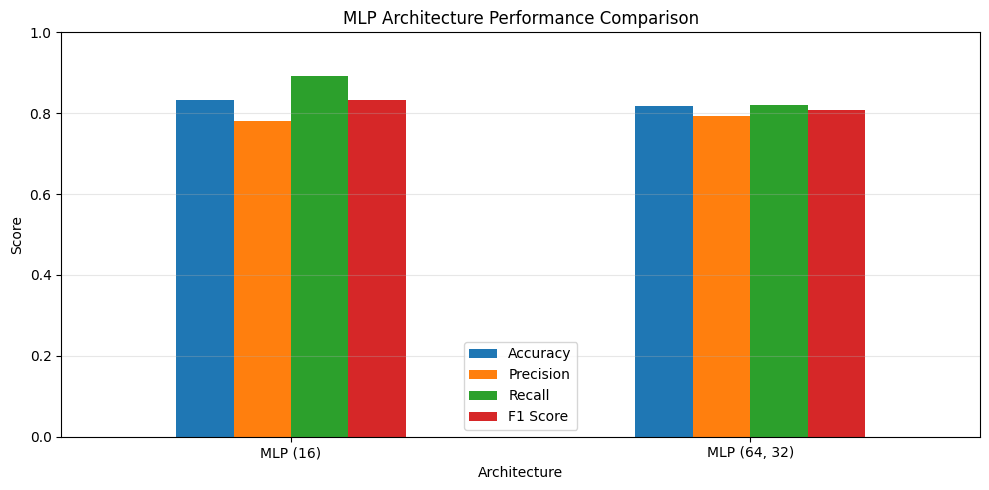

In [9]:
import matplotlib.pyplot as plt

results.set_index("Architecture").plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("MLP Architecture Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Architecture")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

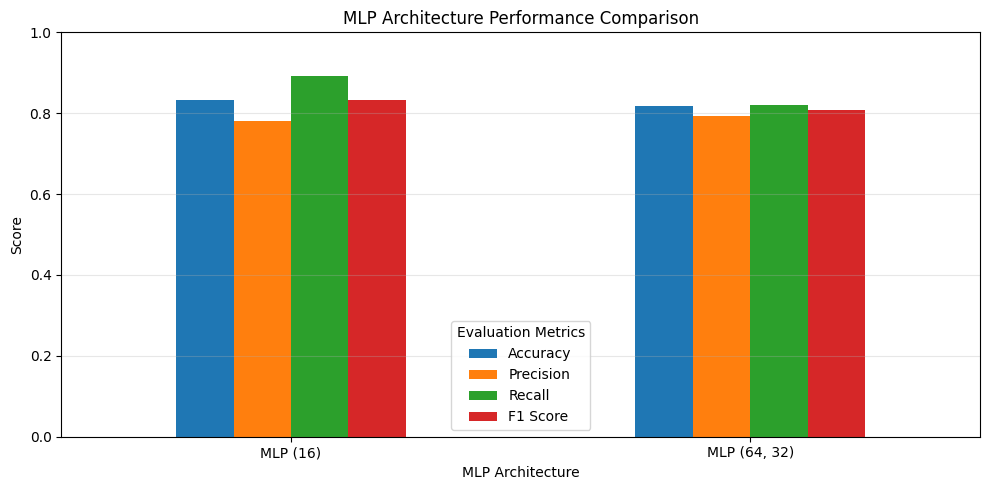

In [10]:
import matplotlib.pyplot as plt

results.set_index("Architecture").plot(
    kind="bar",
    figsize=(10, 5),
    ylim=(0, 1),
    rot=0
)

plt.title("MLP Architecture Performance Comparison")
plt.ylabel("Score")
plt.xlabel("MLP Architecture")
plt.legend(title="Evaluation Metrics")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

In [11]:
from sklearn.neural_network import MLPClassifier

mlp1 = MLPClassifier(
    hidden_layer_sizes=(16,),
    max_iter=1000,
    random_state=42,
    early_stopping=True
)

mlp2 = MLPClassifier(
    hidden_layer_sizes=(64, 32),
    max_iter=1000,
    random_state=42,
    early_stopping=True
)

mlp1.fit(X_train_scaled, y_train)
mlp2.fit(X_train_scaled, y_train)

y_pred1 = mlp1.predict(X_test_scaled)
y_pred2 = mlp2.predict(X_test_scaled)

print("Both MLP models trained successfully!")

Both MLP models trained successfully!


In [12]:
from sklearn.metrics import (
    accuracy_score, precision_score,
    recall_score, f1_score
)
import pandas as pd

results = pd.DataFrame([
    {
        "Architecture": "MLP (16)",
        "Accuracy": accuracy_score(y_test, y_pred1),
        "Precision": precision_score(y_test, y_pred1, zero_division=0),
        "Recall": recall_score(y_test, y_pred1, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred1, zero_division=0)
    },
    {
        "Architecture": "MLP (64, 32)",
        "Accuracy": accuracy_score(y_test, y_pred2),
        "Precision": precision_score(y_test, y_pred2, zero_division=0),
        "Recall": recall_score(y_test, y_pred2, zero_division=0),
        "F1 Score": f1_score(y_test, y_pred2, zero_division=0)
    }
])

display(results.round(4))

,Architecture,Accuracy,Precision,Recall,F1 Score
0,MLP (16),0.8333,0.7812,0.8929,0.8333
1,"MLP (64, 32)",0.8167,0.7931,0.8214,0.8070


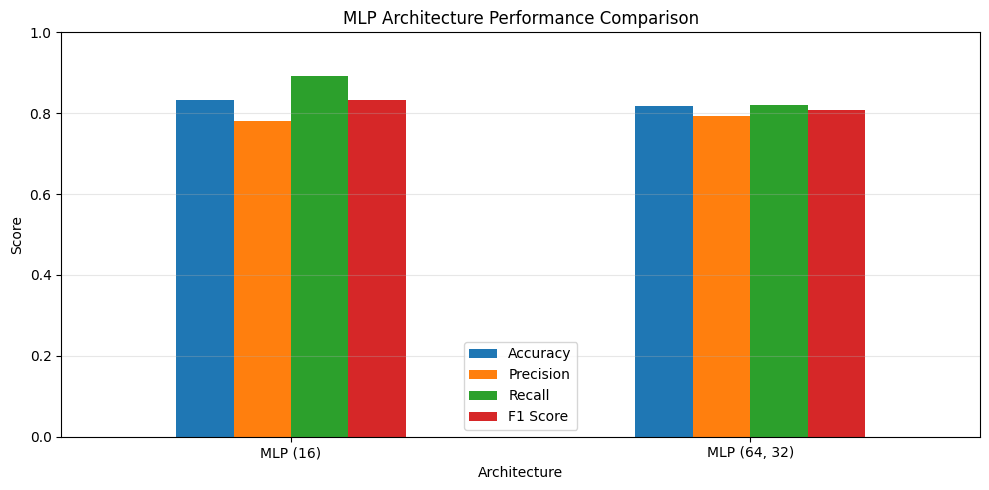

In [13]:
import matplotlib.pyplot as plt

results.set_index("Architecture").plot(
    kind="bar", figsize=(10, 5), ylim=(0, 1), rot=0
)

plt.title("MLP Architecture Performance Comparison")
plt.ylabel("Score")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.savefig("mlp_comparison.png", dpi=300, bbox_inches="tight")
plt.show()

In [14]:
from google.colab import files
files.download("mlp_comparison.png")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>